In [1]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


In [2]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.zeros(2, 3)
c = torch.randn(2, 3)

print(a)
print(b)
print(c)
print(c.shape)

tensor([1., 2., 3.])
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[-1.2162, -0.0122, -0.7021],
        [-0.7871,  0.0565,  0.3375]])
torch.Size([2, 3])


In [3]:
x = torch.tensor([1.0, 2.0, 3.0])
y = torch.tensor([4.0, 5.0, 6.0])

print(x + y)
print(x * y)
print(x.sum())

m = torch.randn(2, 3)
n = torch.randn(3, 2)
print(m @ n)
print((m @ n).shape)

tensor([5., 7., 9.])
tensor([ 4., 10., 18.])
tensor(6.)
tensor([[-4.8647,  2.0921],
        [ 0.2159,  1.6319]])
torch.Size([2, 2])


In [4]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2*x

print(y)

y.backward()
print(x.grad)

tensor(15., grad_fn=<AddBackward0>)
tensor(8.)


In [5]:
import torch.nn as nn

torch.manual_seed(0)

x = torch.linspace(0, 10, 100).reshape(-1, 1)
y = 3 * x + 2 + torch.randn(100, 1)

model = nn.Linear(1, 1)

print(x.shape, y.shape)
print("weight:", model.weight.item())
print("bias:", model.bias.item())

torch.Size([100, 1]) torch.Size([100, 1])
weight: -0.24888432025909424
bias: 0.045122623443603516


In [6]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
    pred = model(x)                # 1. guess
    loss = loss_fn(pred, y)        # 2. measure the error
    optimizer.zero_grad()          # clear old slopes
    loss.backward()                # 3. work out the slopes
    optimizer.step()               # 4. nudge weight and bias

    if epoch % 100 == 0:
        print(epoch, loss.item())

print("weight:", model.weight.item())
print("bias:", model.bias.item())

0 423.33984375
100 1.2526464462280273
200 1.12457275390625
300 1.0772335529327393
400 1.059735894203186
500 1.053268551826477
600 1.0508778095245361
700 1.0499942302703857
800 1.0496677160263062
900 1.0495470762252808
weight: 3.0012598037719727
bias: 2.0283217430114746


In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

image, label = train_data[0]
print(image.shape)
print(label)
print(len(train_data), len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 342kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.19MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.4MB/s]

torch.Size([1, 28, 28])
9
60000 10000


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


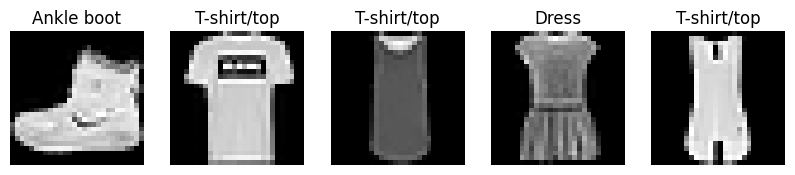

In [8]:
import matplotlib.pyplot as plt

classes = train_data.classes
print(classes)

fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    img, lbl = train_data[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes[lbl])
    ax.axis("off")
plt.show()

In [9]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

device = "cuda" if torch.cuda.is_available() else "cpu"
cnn = SmallCNN().to(device)
print(cnn)

images, labels = next(iter(train_loader))
out = cnn(images.to(device))
print(images.shape)
print(out.shape)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=10, bias=True)
  )
)
torch.Size([64, 1, 28, 28])
torch.Size([64, 10])


In [10]:
test_loader = DataLoader(test_data, batch_size=256)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)

def accuracy(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            correct += (model(imgs).argmax(dim=1) == lbls).sum().item()
    return correct / len(loader.dataset)

for epoch in range(3):
    cnn.train()
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        loss = loss_fn(cnn(imgs), lbls)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch+1}: loss {loss.item():.3f}, test accuracy {accuracy(cnn, test_loader):.3f}")

epoch 1: loss 0.071, test accuracy 0.858
epoch 2: loss 0.303, test accuracy 0.870
epoch 3: loss 0.416, test accuracy 0.885


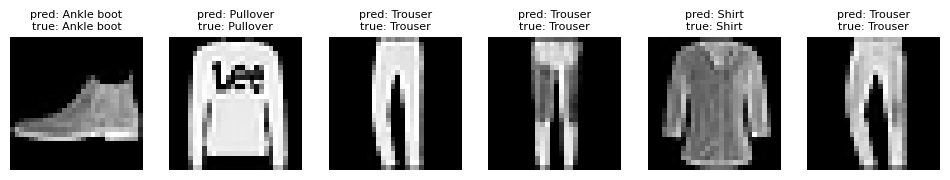

In [11]:
cnn.eval()
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))

for i, ax in enumerate(axes):
    img, true_label = test_data[i]
    with torch.no_grad():
        scores = cnn(img.unsqueeze(0).to(device))
        pred = scores.argmax(dim=1).item()
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"pred: {classes[pred]}\ntrue: {classes[true_label]}", fontsize=8)
    ax.axis("off")

plt.show()